# PSCC-Net on TGIF — results

Official pretrained PSCC-Net, zero-shot on the TGIF testing split (SD2-sp and PS-sp). All numbers are computed on the **3 shared resamples** and reported as **mean ± std over the resamples** (sample std, ddof = 1).

Each resample keeps its 275 source images and their 3,300 forged images (6 SD + 6 PS per source). **All authentic versions** of those sources are used: the original plus the resized 512 and 1024 crops, so 825 authentic images per resample (`AUTHENTIC_VERSIONS` in Settings). Set it to `("orig",)` for the team protocol (275 authentic per resample), which is what the other models in the benchmark use.

| Section | Content |
|---|---|
| 4 | Main results: detection and localization (team table format) |
| 5 | Localization threshold: 0.5 vs 0.2 |
| 6 | Gated vs ungated localization |
| 7 | Localization per category |
| 9 | Per-image file in the shared template |

Inputs: `detection.csv` and `localization.csv` from `infer.py`, one run per localization threshold. Detection uses a 0.5 threshold on the image score in every section; the localization threshold is set per run.

## 1. Settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RUNS = {                                   # localization threshold -> folder with detection.csv + localization.csv
    0.5: Path("results/thr05"),
    0.2: Path("results/thr02"),
}
MAIN_THR = 0.2                             # localization threshold used for the main tables
AUTHENTIC_VERSIONS = ("orig", "512", "1024")   # ("orig",) = team protocol
RESAMPLE_DIR = Path("resamples")           # shared resample_1.csv ... resample_3.csv
OUT = Path("results/tables")
FIG = Path("figures")
K = (1, 2, 3)

OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)

## 2. Load

In [2]:
def basename(p):
    return str(p).replace("\\", "/").rsplit("/", 1)[-1]

COLS = ["image_id", "source_id", "category", "generator", "mask_type", "variant", "label",
        "width", "height", "file", "mask_file", "key"]

rs = {k: pd.read_csv(RESAMPLE_DIR / f"resample_{k}.csv") for k in K}
for k in K:
    rs[k]["key"] = rs[k]["file"].map(basename)

def extra_authentic(det, sources):
    """Resized authentic versions (512 / 1024) of the given source images, in the resample format."""
    a = det[(det["label"] == 0) & det["orig_size"].isin([v for v in AUTHENTIC_VERSIONS if v != "orig"])]
    a = a[a["source_id"].isin(sources)]
    return pd.DataFrame({
        "image_id": "real_" + a["source_id"].astype(str) + "_" + a["orig_size"],
        "source_id": a["source_id"], "category": a["category"], "generator": "real",
        "mask_type": "none", "variant": -1, "label": 0, "width": a["width"], "height": a["height"],
        "file": a["filename"], "mask_file": "", "key": a["key"]})

def load(folder):
    det = pd.read_csv(folder / "detection.csv", dtype={"orig_size": str}).drop_duplicates("filename", keep="last")
    loc = pd.read_csv(folder / "localization.csv").drop_duplicates("filename", keep="last")
    det["key"] = det["filename"].map(basename)
    loc["key"] = loc["filename"].map(basename)
    det["source_id"] = pd.to_numeric(det["image_id"], errors="coerce")
    det["orig_size"] = det["orig_size"].str.replace(r"\.0$", "", regex=True)
    d = det[["key", "score", "pred"]].merge(
        loc[["key", "TP", "FP", "FN", "TN", "iou", "dice", "pix_precision", "pix_recall"]], on="key", how="left")
    sets = {}
    for k in K:
        base = rs[k][COLS]
        if "orig" not in AUTHENTIC_VERSIONS:
            base = base[base["label"] == 1]
        extra = extra_authentic(det, set(rs[k]["source_id"]))
        s = pd.concat([base, extra], ignore_index=True).merge(d, on="key", how="left")
        assert s["score"].notna().all(), f"resample {k}: {int(s['score'].isna().sum())} images without results"
        assert s.loc[s.label == 1, "TP"].notna().all(), f"resample {k}: forged images without a mask row"
        sets[k] = s
    return sets

data = {thr: load(f) for thr, f in RUNS.items()}
for thr, sets in data.items():
    for k in K:
        s = sets[k]
        print(f"threshold {thr}, resample_{k}: {len(s)} images "
              f"({int((s.label == 0).sum())} authentic, {int((s.label == 1).sum())} forged, "
              f"{s.source_id.nunique()} sources)")

threshold 0.5, resample_1: 4125 images (825 authentic, 3300 forged, 275 sources)
threshold 0.5, resample_2: 4125 images (825 authentic, 3300 forged, 275 sources)
threshold 0.5, resample_3: 4125 images (825 authentic, 3300 forged, 275 sources)
threshold 0.2, resample_1: 4125 images (825 authentic, 3300 forged, 275 sources)
threshold 0.2, resample_2: 4125 images (825 authentic, 3300 forged, 275 sources)
threshold 0.2, resample_3: 4125 images (825 authentic, 3300 forged, 275 sources)


## 3. Metric functions

* Detection: positive = manipulated, threshold 0.5 on the detection score. ROC-AUC from the continuous score.
* Localization: forged images only. **Macro** = mean of per-image metrics; **pooled** = TP/FP/FN summed over all pixels. Pixel F1 = Dice for binary masks.
* **Ungated**: the mask is scored on every forged image. **Gated**: if the detector says authentic, the predicted mask is empty, so TP = FP = 0 and IoU, Dice, precision and recall are 0 for that image.

In [3]:
def div(a, b):
    return a / b if b else np.nan

def roc_auc(y, s):
    y = np.asarray(y); s = np.asarray(s, dtype=float)
    n_pos, n_neg = int((y == 1).sum()), int((y == 0).sum())
    if n_pos == 0 or n_neg == 0:
        return np.nan
    r = pd.Series(s).rank(method="average").to_numpy()
    return (r[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def detection(d):
    y, p = d["label"].to_numpy(), (d["score"].to_numpy() > 0.5).astype(int)
    tp = int(((p == 1) & (y == 1)).sum()); fp = int(((p == 1) & (y == 0)).sum())
    tn = int(((p == 0) & (y == 0)).sum()); fn = int(((p == 0) & (y == 1)).sum())
    prec, rec = div(tp, tp + fp), div(tp, tp + fn)
    return {"Accuracy": div(tp + tn, len(y)), "Precision": prec, "Recall": rec,
            "F1": div(2 * prec * rec, prec + rec), "ROC-AUC": roc_auc(y, d["score"]),
            "Balanced acc.": np.mean([rec, div(tn, tn + fp)])}

def gate(f):
    """Zero the mask of every forged image the detector calls authentic."""
    g = f.copy()
    off = g["score"] <= 0.5
    g.loc[off, "FN"] = g.loc[off, "TP"] + g.loc[off, "FN"]
    g.loc[off, ["TP", "FP", "iou", "dice", "pix_precision", "pix_recall"]] = 0
    return g

def loc_macro(f):
    return {"IoU": f["iou"].mean(), "Dice": f["dice"].mean(),
            "Precision": f["pix_precision"].mean(), "Recall": f["pix_recall"].mean()}

def loc_pooled(f):
    tp, fp, fn = f["TP"].sum(), f["FP"].sum(), f["FN"].sum()
    return {"IoU": div(tp, tp + fp + fn), "Dice": div(2 * tp, 2 * tp + fp + fn),
            "Precision": div(tp, tp + fp), "Recall": div(tp, tp + fn)}

def over_resamples(fn, sets, select=lambda d: d):
    """fn applied to each resample -> DataFrame (rows: resamples) and a 'mean ± std' Series."""
    per = pd.DataFrame({k: fn(select(sets[k])) for k in K}).T
    pm = per.mean().map("{:.4f}".format) + " ± " + per.std(ddof=1).map("{:.4f}".format)
    return per, pm

forged = lambda d: d[d["label"] == 1]

## 4. Main results (ungated)

In [4]:
main = data[MAIN_THR]
rows_det, rows_mac, rows_pool = {}, {}, {}
for name, sel in [("all", lambda d: d),
                  ("PS", lambda d: d[(d.generator == "PS") | (d.label == 0)]),
                  ("SD", lambda d: d[(d.generator == "SD") | (d.label == 0)])]:
    rows_det[name] = over_resamples(detection, main, sel)[1]
    rows_mac[name] = over_resamples(loc_macro, main, lambda d, s=sel: forged(s(d)))[1]
    rows_pool[name] = over_resamples(loc_pooled, main, lambda d, s=sel: forged(s(d)))[1]

t_det, t_mac, t_pool = (pd.DataFrame(r).T for r in (rows_det, rows_mac, rows_pool))
print("Table 1: Detection (score > 0.5)"); display(t_det)
print(f"Table 2a: Localization, macro (mean of per-image metrics), threshold {MAIN_THR}"); display(t_mac)
print(f"Table 2b: Localization, pooled (pixels summed), threshold {MAIN_THR}"); display(t_pool)

Table 1: Detection (score > 0.5)


,Accuracy,Precision,Recall,F1,ROC-AUC,Balanced acc.
all,0.6561 ± 0.0085,0.8572 ± 0.0009,0.6840 ± 0.0124,0.7609 ± 0.0078,0.6081 ± 0.0029,0.6141 ± 0.0031
PS,0.6463 ± 0.0059,0.7537 ± 0.0010,0.6974 ± 0.0124,0.7244 ± 0.0069,0.6180 ± 0.0025,0.6208 ± 0.0028
SD,0.6286 ± 0.0062,0.7464 ± 0.0017,0.6707 ± 0.0124,0.7065 ± 0.0073,0.5982 ± 0.0032,0.6075 ± 0.0034


Table 2a: Localization, macro (mean of per-image metrics), threshold 0.2


,IoU,Dice,Precision,Recall
all,0.3346 ± 0.0053,0.4106 ± 0.0065,0.4683 ± 0.0089,0.4814 ± 0.0087
PS,0.4513 ± 0.0064,0.5446 ± 0.0081,0.5886 ± 0.0120,0.6211 ± 0.0085
SD,0.2179 ± 0.0055,0.2766 ± 0.0063,0.3480 ± 0.0062,0.3416 ± 0.0094


Table 2b: Localization, pooled (pixels summed), threshold 0.2


,IoU,Dice,Precision,Recall
all,0.3645 ± 0.0023,0.5343 ± 0.0024,0.4569 ± 0.0073,0.6436 ± 0.0127
PS,0.4480 ± 0.0039,0.6188 ± 0.0037,0.5146 ± 0.0096,0.7764 ± 0.0102
SD,0.2841 ± 0.0055,0.4425 ± 0.0066,0.3905 ± 0.0083,0.5107 ± 0.0153


## 5. Localization threshold: 0.5 vs 0.2 (ungated, macro)

In [5]:
t_thr = pd.DataFrame({f"threshold {thr}": over_resamples(loc_macro, data[thr], forged)[1] for thr in RUNS})
display(t_thr)

,threshold 0.5,threshold 0.2
IoU,0.2096 ± 0.0032,0.3346 ± 0.0053
Dice,0.2681 ± 0.0042,0.4106 ± 0.0065
Precision,0.4531 ± 0.0058,0.4683 ± 0.0089
Recall,0.2456 ± 0.0036,0.4814 ± 0.0087


## 6. Gated vs ungated (threshold 0.2, macro)

In [6]:
t_gate = pd.DataFrame({
    "not gated": over_resamples(loc_macro, data[0.2], forged)[1],
    "gated": over_resamples(loc_macro, data[0.2], lambda d: gate(forged(d)))[1],
})
display(t_gate)

,not gated,gated
IoU,0.3346 ± 0.0053,0.2422 ± 0.0051
Dice,0.4106 ± 0.0065,0.2953 ± 0.0058
Precision,0.4683 ± 0.0089,0.3388 ± 0.0075
Recall,0.4814 ± 0.0087,0.3456 ± 0.0026


## 7. Localization per category (main threshold, ungated, macro)

,IoU,Dice,Precision,Recall,n_sources
skis,0.1192 ± 0.0116,0.1532 ± 0.0147,0.2060 ± 0.0141,0.1721 ± 0.0203,35
tennis racket,0.1765 ± 0.0095,0.2302 ± 0.0127,0.2716 ± 0.0157,0.3235 ± 0.0129,38
scissors,0.1932 ± 0.0297,0.2436 ± 0.0376,0.3957 ± 0.0500,0.2551 ± 0.0419,7
snowboard,0.1965 ± 0.0114,0.2522 ± 0.0165,0.3209 ± 0.0158,0.3132 ± 0.0207,16
sports ball,0.2500 ± 0.0157,0.3041 ± 0.0198,0.3486 ± 0.0219,0.3714 ± 0.0235,18
kite,0.2754 ± 0.0258,0.3378 ± 0.0298,0.4261 ± 0.0340,0.3803 ± 0.0308,25
airplane,0.3556 ± 0.0124,0.4395 ± 0.0156,0.5007 ± 0.0062,0.5459 ± 0.0272,22
stop sign,0.4454 ± 0.0471,0.5347 ± 0.0475,0.5772 ± 0.0553,0.6465 ± 0.0083,16
hair drier,0.4468 ± 0.0000,0.5429 ± 0.0000,0.7144 ± 0.0000,0.5101 ± 0.0000,2
sheep,0.4632 ± 0.0218,0.5683 ± 0.0245,0.5940 ± 0.0276,0.6917 ± 0.0258,22


hair drier has only 2 source images per resample: treat its row as anecdotal.


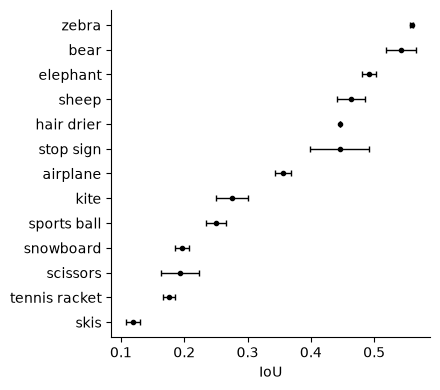

In [7]:
cats = sorted(main[1]["category"].unique())
per_cat = {}
for c in cats:
    per, _ = over_resamples(loc_macro, main, lambda d, c=c: forged(d[d.category == c]))
    per_cat[c] = per
t_cat = pd.DataFrame({c: p.mean().map("{:.4f}".format) + " ± " + p.std(ddof=1).map("{:.4f}".format)
                      for c, p in per_cat.items()}).T
t_cat["n_sources"] = [main[1].loc[main[1].category == c, "source_id"].nunique() for c in t_cat.index]
order = sorted(cats, key=lambda c: per_cat[c]["IoU"].mean())
t_cat = t_cat.loc[order]
display(t_cat)
print("hair drier has only 2 source images per resample: treat its row as anecdotal.")

m = pd.Series({c: per_cat[c]["IoU"].mean() for c in order})
s = pd.Series({c: per_cat[c]["IoU"].std(ddof=1) for c in order})
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.errorbar(m, np.arange(len(m)), xerr=s, fmt="o", color="black", ms=3, lw=1, capsize=2)
ax.set_yticks(range(len(m)))
ax.set_yticklabels(m.index)
ax.set_xlabel("IoU")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "iou_by_category.pdf")
fig.savefig(FIG / "iou_by_category.png", dpi=200)
plt.show()

## 8. Save tables

In [8]:
tables = {"table1_detection": t_det, "table2a_localization_macro": t_mac,
          "table2b_localization_pooled": t_pool, "localization_threshold": t_thr,
          "localization_gated_vs_ungated": t_gate, "localization_by_category": t_cat}
md_out = []
for name, t in tables.items():
    t.to_csv(OUT / f"{name}.csv")
    hdr = [t.index.name or ""] + [str(c) for c in t.columns]
    md_out += [f"### {name}", "", "| " + " | ".join(hdr) + " |", "|" + "---|" * len(hdr)]
    md_out += ["| " + " | ".join([str(i)] + [str(v) for v in r]) + " |" for i, r in zip(t.index, t.values)]
    md_out += [""]
(OUT / "tables.md").write_text("\n".join(md_out), encoding="utf-8")
print("Saved", len(tables), "tables to", OUT)

Saved 6 tables to results\tables


## 9. Per-image file (shared template)

One row per unique image used in any resample, same columns as `TruFor/outputs/tables/trufor_per_image.csv`, at the main threshold. Resized authentic images get the id `real_<source>_<512|1024>`.

In [9]:
TEMPLATE = ["model", "image_id", "source_id", "category", "generator", "mask_type", "variant", "label",
            "width", "height", "file", "mask_file", "in_resample_1", "in_resample_2", "in_resample_3",
            "det_score", "det_pred", "det_correct", "loc_iou", "loc_dice", "loc_pixel_precision",
            "loc_pixel_recall", "loc_pixel_f1", "loc_tp", "loc_fp", "loc_fn", "loc_tn"]

u = pd.concat(main.values()).drop_duplicates("image_id").copy()
for k in K:
    u[f"in_resample_{k}"] = u["image_id"].isin(main[k]["image_id"]).astype(int)
u["model"] = "PSCC-Net"
u["det_score"] = u["score"]
u["det_pred"] = (u["score"] > 0.5).astype(int)
u["det_correct"] = (u["det_pred"] == u["label"]).astype(int)
u = u.rename(columns={"iou": "loc_iou", "dice": "loc_dice", "pix_precision": "loc_pixel_precision",
                      "pix_recall": "loc_pixel_recall", "TP": "loc_tp", "FP": "loc_fp", "FN": "loc_fn", "TN": "loc_tn"})
u["loc_pixel_f1"] = u["loc_dice"]
loc_cols = [c for c in TEMPLATE if c.startswith("loc_")]
u.loc[u["label"] == 0, loc_cols] = np.nan
for c in ("loc_tp", "loc_fp", "loc_fn", "loc_tn"):
    u[c] = u[c].astype("Int64")
u[TEMPLATE].sort_values("image_id").to_csv(OUT / "pscc_per_image.csv", index=False, float_format="%.10g")
print(len(u), "rows ->", OUT / "pscc_per_image.csv")

5085 rows -> results\tables\pscc_per_image.csv
